# 02 Oxford Flowers - Replica Chollet ch17 (punto 2)


Abrir en Colab GPU T4. Replica del ejercicio de difusion del capitulo 17: UNet 128x128 sobre Oxford Flowers 102 (8189 flores, 102 especies), 80 epocas. SD3 preentrenado como extra. El VAE del capitulo no se incluye; el ejercicio replicado es el modelo de difusion.


### 0 Setup (apuntes REPOS 3.2)
Keras + TF + datasets + clean-fid. Sin torch aqui para no pelear VRAM con TF.


In [1]:
%pip install -q keras keras-hub tensorflow datasets clean-fid
import keras; print(keras.__version__)


3.13.2


### 1 Datos (consigna punto 2 + libro ch17)
Oxford 102flowers.tgz 8189 imgs. Como se cae en Colab, fallback espejo HF huggan/flowers-102, mismas imagenes.


In [2]:
# Oxford directo se cae en Colab (timeout). Espejo HF huggan/flowers-102 (mismas 8189).
try:
    import os
    fpath = keras.utils.get_file(origin="https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz", extract=True)
    images_dir = os.path.join(fpath, "jpg")
    print("oxford OK", len(os.listdir(images_dir)))
    USE_HF=False
except Exception as e:
    print("oxford fallo, uso espejo HF:", e)
    USE_HF=True
    images_dir=None


oxford fallo, uso espejo HF: URL fetch failure on https://www.robots.ox.ac.uk/~vgg/data/flowers/102/102flowers.tgz: None -- [Errno 110] Connection timed out


### 2 Dataset 128x128 (libro: crop_to_aspect_ratio)
128x128 sin distorsion, rebatch 32, prefetch. Es lo que entra en T4.


dataset_infos.json:   0%|          | 0.00/677 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8189 [00:00<?, ? examples/s]

Dataset({
    features: ['image'],
    num_rows: 8189
})
batches listas


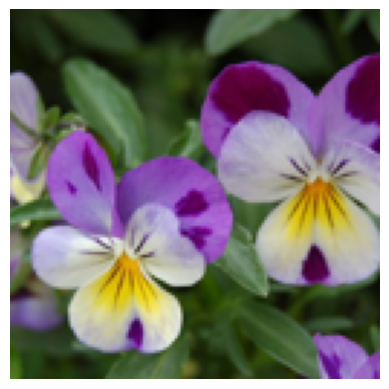

In [3]:
batch_size=32
image_size=128
import tensorflow as tf
if not USE_HF:
    dataset = keras.utils.image_dataset_from_directory(images_dir, labels=None, image_size=(image_size,image_size), crop_to_aspect_ratio=True)
    dataset = dataset.rebatch(batch_size, drop_remainder=True)
else:
    from datasets import load_dataset
    hf = load_dataset("huggan/flowers-102-categories", split="train")
    print(hf)
    def gen():
        import numpy as np
        from PIL import Image
        import io
        for ex in hf:
            im=ex["image"]
            if not isinstance(im, Image.Image):
                im=Image.open(io.BytesIO(im["bytes"]) if isinstance(im,dict) else im)
            im=im.convert("RGB")
            w,h=im.size; s=min(w,h)
            im=im.crop(((w-s)//2,(h-s)//2,(w+s)//2,(h+s)//2)).resize((image_size,image_size))
            yield __import__("numpy").array(im)
    dataset = tf.data.Dataset.from_generator(gen, output_signature=tf.TensorSpec((128,128,3), tf.uint8))
    dataset = dataset.shuffle(1024, seed=42)  # mezcla las especies antes de agrupar
    dataset = dataset.batch(batch_size, drop_remainder=True).prefetch(tf.data.AUTOTUNE)
print("batches listas")
import matplotlib.pyplot as plt
import numpy as np
bt=next(iter(dataset))
arr=bt.numpy() if hasattr(bt,"numpy") else np.array(bt)
plt.imshow(arr[0].astype("uint8")); plt.axis("off"); plt.show()


### 3 UNet denoiser (libro Fig 17.9 + NOTAS 05)
Down 128->16, medio, up 16->128 con skips concatenados. Predice ruido, init ceros = asume sin ruido.


In [4]:
from keras import layers
def residual_block(x, width):
    iw = x.shape[3]
    res = x if iw==width else layers.Conv2D(width,1)(x)
    x = layers.BatchNormalization(center=False, scale=False)(x)
    x = layers.Conv2D(width,3,padding="same",activation="swish")(x)
    x = layers.Conv2D(width,3,padding="same")(x)
    return x + res
def get_model(image_size, widths, block_depth):
    ni = keras.Input(shape=(image_size,image_size,3))
    nr = keras.Input(shape=(1,1,1))
    x = layers.Conv2D(widths[0],1)(ni)
    n = layers.UpSampling2D(image_size, interpolation="nearest")(nr)
    x = layers.Concatenate()([x,n])
    skips=[]
    import copy
    # down
    # ponytail: widths [32,64,96,128] como libro, no mas grande en T4
    for w in widths[:-1]:
        for _ in range(block_depth):
            x=residual_block(x,w); skips.append(x)
        x=layers.AveragePooling2D(2)(x)
    for _ in range(block_depth): x=residual_block(x,widths[-1])
    for w in reversed(widths[:-1]):
        x=layers.UpSampling2D(2, interpolation="bilinear")(x)
        for _ in range(block_depth):
            x=layers.Concatenate()([x, skips.pop()])
            x=residual_block(x,w)
    out=layers.Conv2D(3,1,kernel_initializer="zeros")(x)
    return keras.Model([ni,nr], out)
m=get_model(128,[32,64,96,128],2); m.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 1, 1, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        128 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 128, 128,  │          0 │ input_layer_1[0]… │
│ (UpSampling2D)      │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128, 128,  │          0 │ conv2d[0][0],     │
│ (Concatenate)       │ 33)               │            │ up_sampling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │         66 │ concatenate[0][0] │
│ (BatchNormalizatio… │ 33)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      9,536 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      1,088 │ concatenate[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 128,  │          0 │ conv2d_3[0][0],   │
│                     │ 32)               │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         64 │ add[0][0]         │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 128, 128,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_4[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 128, 128,  │          0 │ conv2d_5[0][0],   │
│                     │ 32)               │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d   │ (None, 64, 64,    │          0 │ add_1[0][0]       │
│ (AveragePooling2D)  │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │         64 │ average_pooling2… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 64, 64,    │     18,496 │ batch_normalizat

 Total params: 1,943,525 (7.41 MB)

 Trainable params: 1,940,707 (7.40 MB)

 Non-trainable params: 2,818 (11.01 KB)

### 4 Schedule coseno (NOTAS 03 + libro List 17.7)\nMantiene ruido^2+senal^2=1. t=1 puro ruido, t=0 senal.


In [5]:
from keras import ops
def diffusion_schedule(times, min_signal=0.02, max_signal=0.95):
    sa=ops.cast(ops.arccos(max_signal),"float32")
    ea=ops.cast(ops.arccos(min_signal),"float32")
    ang=sa+times*(ea-sa)
    return ops.sin(ang), ops.cos(ang)
ts=ops.arange(0.0,1.0,0.01)
nr,sr=diffusion_schedule(ts)
print("schedule OK", nr.shape)


schedule OK (100,)


### 5 Modelo difusion (libro: denoise/call/generate/compute_loss)
Normaliza, mete ruido segun schedule, denoisea, loss MAE ruido real vs predicho.


In [6]:
class DiffusionModel(keras.Model):
    def __init__(self, image_size, widths, block_depth):
        super().__init__()
        self.image_size=image_size
        self.denoiser=get_model(image_size,widths,block_depth)
        self.seed_generator=keras.random.SeedGenerator()
        self.loss_fn=keras.losses.MeanAbsoluteError()
        self.normalizer=keras.layers.Normalization()
    def denoise(self, noisy, nr, sr):
        pm=self.denoiser([noisy,nr])
        return (noisy-nr*pm)/sr, pm
    def call(self, images):
        import keras
        images=self.normalizer(images)
        b=images.shape[0] or batch_size
        nm=keras.random.normal((b,self.image_size,self.image_size,3), seed=self.seed_generator)
        dt=keras.random.uniform((b,1,1,1),0.0,1.0, seed=self.seed_generator)
        nr,sr=diffusion_schedule(dt)
        noisy=sr*images+nr*nm
        pi,pm=self.denoise(noisy,nr,sr)
        return pi,pm,nm
    def compute_loss(self,x,y,yp,sample_weight=None,training=True):
        _,pm,nm=yp
        return self.loss_fn(nm,pm)
    def generate(self, nimg, steps):
        import keras
        from keras import ops
        noisy=keras.random.normal((nimg,self.image_size,self.image_size,3), seed=self.seed_generator)
        step=1.0/steps
        for s in range(steps):
            dt=ops.ones((nimg,1,1,1))-s*step
            nr,sr=diffusion_schedule(dt)
            pi,pn=self.denoise(noisy,nr,sr)
            nnr,nsr=diffusion_schedule(dt-step)
            noisy=nsr*pi+nnr*pn
        imgs=self.normalizer.mean+pi*self.normalizer.variance**0.5
        return ops.clip(imgs,0.0,255.0)


### 6 Compile (libro: AdamW + InverseTimeDecay + EMA)
Adapt normalizer primero. EMA cada 100 estabiliza. Ver NOTAS 03.


In [7]:
model=DiffusionModel(128,[32,64,96,128],2)
model.normalizer.adapt(dataset)
model.compile(optimizer=keras.optimizers.AdamW(learning_rate=keras.optimizers.schedules.InverseTimeDecay(1e-3,1000,0.1), use_ema=True, ema_overwrite_frequency=100))
print("compilado")


compilado


### 7 Entrena 80 epocas y visualiza cada 10
18 imagenes cada 10 epocas con generate(18,20). Esperado: ruido -> manchas -> petalos.


In [ ]:
import matplotlib.pyplot as plt
from keras import ops

class Viz(keras.callbacks.Callback):
    def __init__(self, every=10):
        super().__init__()
        self.every = every
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every != 0:
            return
        g = self.model.generate(18, 20)
        plt.figure(figsize=(12, 6))
        k = 0
        for r in range(3):
            for c in range(6):
                plt.subplot(3, 6, k + 1)
                plt.imshow(ops.convert_to_numpy(g[k]).astype("uint8"))
                plt.axis("off")
                k += 1
        plt.tight_layout(); plt.show(); plt.close()

EPOCHS = 80
STEPS_PER_EPOCH = 8189 // batch_size  # 255 lotes completos por epoca
train_ds = dataset.repeat()
model.fit(
    train_ds,
    epochs=EPOCHS,
    steps_per_epoch=STEPS_PER_EPOCH,
    shuffle=False,  # el dataset ya viene barajado
    callbacks=[
        Viz(every=10),
        keras.callbacks.ModelCheckpoint("diffusion_flowers.weights.h5", save_weights_only=True),
        keras.callbacks.TerminateOnNaN(),
    ],
)
print(f"entrenamiento listo: {EPOCHS} epocas; pesos en diffusion_flowers.weights.h5")

### 8 Metricas FID con 1000 imagenes
1000 generadas vs 1000 reales. Inception en CPU, batch 16, para no chocar con TF/GPU.


In [ ]:
# FID autocontenido: genera 1000 imagenes y usa 1000 reales.
import os, glob, shutil, gc
import torch
from keras import ops
from PIL import Image
import matplotlib.pyplot as plt
from cleanfid import fid

N = 1000
B = 10
STEPS = 20
for d in ["gen_flowers", "real_flowers"]:
    if os.path.exists(d):
        shutil.rmtree(d)
    os.makedirs(d)

k = 0
while k < N:
    g = model.generate(min(B, N - k), STEPS)
    arr = ops.convert_to_numpy(g)
    del g
    gc.collect()
    for i in range(arr.shape[0]):
        if k >= N:
            break
        Image.fromarray(arr[i].astype("uint8")).save("gen_flowers/%04d.png" % k)
        k += 1
    print(f"gen {k}/{N}")

k = 0
for batch in dataset.take(32):  # 32 lotes x 32 = 1024 imagenes
    arr = batch.numpy()
    for j in range(len(arr)):
        if k >= N:
            break
        Image.fromarray(arr[j].astype("uint8")).save("real_flowers/%04d.png" % k)
        k += 1
    if k >= N:
        break
print("real", k)

g2 = model.generate(6, STEPS)
a2 = ops.convert_to_numpy(g2)
plt.figure(figsize=(12, 4))
for kk in range(6):
    plt.subplot(2, 3, kk + 1)
    plt.imshow(a2[kk].astype("uint8"))
    plt.axis("off")
plt.tight_layout(); plt.show()

print("FID:", fid.compute_fid("gen_flowers/", "real_flowers/", device=torch.device("cpu"), batch_size=16, num_workers=0))

### 9 Extra libro: SD3 sin entrenar (ch17 Text-to-image)
keras_hub TextToImage stable_diffusion_3_medium, solo inferencia con prompt girasol.


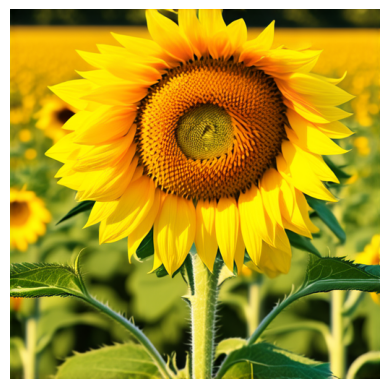

In [11]:
# Extra libro: SD3 pretrained sin entrenar (text-to-image) + mostrar
import keras_hub
import matplotlib.pyplot as plt
task=keras_hub.models.TextToImage.from_preset("stable_diffusion_3_medium", image_shape=(512,512,3), dtype="float16")
img=task.generate("a close-up photo of a sunflower field, high detail")
plt.imshow(img); plt.axis("off"); plt.show()
